# Do modelo de fundação ao SFT: experimento prático com o Qwen2.5

(A) um modelo pré-treinado,
(B) um modelo já ajustado para instruções e (C) o mesmo modelo-base após um pequeno SFT nosso.

O experimento usa a família Qwen2.5 de 0,5 bilhão de parâmetros e Hugging Face. Execute em um ambiente com GPU, preferencialmente Google Colab: **Ambiente de execução → Alterar tipo de ambiente de execução → GPU**.

> **Limitação didática:** o conjunto criado aqui é pequeno e artificial. Ele serve para demonstrar o mecanismo de SFT, não para produzir um assistente robusto. O SFT pode melhorar os comportamentos exemplificados e, ao mesmo tempo, piorar outros comportamentos.

## Pré-Treinamento dos Modelos de Fundação

Considere um modelo de linguagem autoregressivo, como os modelos GPT. Durante o pré-treinamento, ele aprende a estimar:
$$
P(x_t \mid x_1,x_2,\ldots,x_{t-1})
$$

Ou seja, a distribuição de probabilidade do próximo token, condicionada aos tokens anteriores.

Por exemplo, ao receber:
_A capital do Brasil é ..._

o modelo aprende a atribuir uma probabilidade elevada a tokens como _Brasília_.

O treinamento minimiza a **entropia cruzada** entre o próximo token observado e a distribuição prevista pelo modelo:
$$
\mathcal{L}(\theta) =
-\sum_{t=1}^{T}
\log P_\theta(x_t\mid x_{<t})
$$

Os parâmetros $\theta$ são ajustados por otimização, normalmente com variantes do gradiente descendente e **backpropagation**.


Nesse processo o modelo "aprende":

- **Embeddings**: representações vetoriais dos tokens.
- **Atenção e camadas Transformer**: permitem combinar informações de diferentes posições do contexto. _O mesmo token pode adquirir representações contextuais diferentes dependendo da frase em que aparece._
- **Camadas intermediárias**: aprendem representações contextuais e regularidades sintáticas, semânticas e outras estruturas úteis para prever tokens.
- **Camada de saída**: converte a representação final em uma distribuição de probabilidades sobre o vocabulário.



O resultado é um modelo que "codifica" o conhecimento dos dados de treinamento e é capaz de produzir continuações razoavelmente plausíveis de um texto. Temos um modelo que completa textos muito bem, mas isso não garante que ele se comporte como um assistente.

## Instruction Tunning

Se fornecemos ao modelo pré-treinado a frase _Explique a diferença entre regressão e classificação._, o modelo  pré-treinado pode continuar o texto de várias maneiras. Talvez produza uma explicação, talvez uma pergunta semelhante, talvez reproduza um trecho de um livro didático. Ele aprendeu a prever a continuação do texto, mas ainda não foi treinado para obedecer a instruções de um usuário.


1. **Pré-treinamento**:
Grandes volumes de texto; previsão do próximo token

2. **Instruction tuning**: Exemplos de instruções e respostas desejadas

3. **Modelo ajustado para seguir instruções**: Responde a perguntas, resume, traduz e segue orientações

O modelo é treinado novamente, agora com exemplos do comportamento desejado.

<br>

| Instrução	| Resposta desejada |
|-|-|
|Traduza para inglês: "Bom dia."|	Good morning.|
|Resuma: "A empresa registrou..."	|A empresa apresentou crescimento...|
|Qual é a capital do Brasil?	|A capital do Brasil é Brasília.|
|Classifique o sentimento: "Adorei o produto!"	|Positivo.|

<br>

Continuamos usando a previsão do próximo token e uma função de perda semelhante à do pré-treinamento. A diferença fundamental está nos dados usados para calcular a perda. Em geral, a perda é calculada sobre os tokens da resposta esperada, considerando a instrução e o contexto como entrada. O processo de otimização ajusta os parâmetros para aumentar a probabilidade das respostas exemplificadas.

Portanto, não precisamoscriar um modelo totalmente novo. Partimos do modelo de fundação e continuamos seu treinamento, produzindo um modelo ajustado para seguir instruções.

Esse processo é conhecido como **Supervised Fine-Tuning (SFT)**, e o instruction tuning é uma de suas aplicações mais comuns.

## 1. Imports



In [ ]:
# %pip install -q --upgrade \
%pip install --upgrade \
    "huggingface-hub>=1.32.0,<2.0" \
    "transformers>=4.48.0,<5.0" \
    "datasets>=4.8.5,<5.0" \
    "peft>=0.14.0" \
    "trl>=0.15.0" \
    "accelerate>=1.2.0" \
    sentencepiece \
    jedi

  Using cached transformers-4.57.6-py3-none-any.whl.metadata (43 kB)
  Using cached trl-1.16.0-py3-none-any.whl.metadata (12 kB)
  Using cached jedi-0.20.1-py2.py3-none-any.whl.metadata (23 kB)
INFO: pip is looking at multiple versions of transformers to determine which version is compatible with other requirements. This could take a while.
  Using cached transformers-4.57.5-py3-none-any.whl.metadata (43 kB)
  Using cached transformers-4.57.4-py3-none-any.whl.metadata (43 kB)
  Using cached transformers-4.57.3-py3-none-any.whl.metadata (43 kB)
  Using cached transformers-4.57.2-py3-none-any.whl.metadata (43 kB)
  Using cached transformers-4.57.1-py3-none-any.whl.metadata (43 kB)
  Using cached transformers-4.56.2-py3-none-any.whl.metadata (40 kB)
  Using cached transformers-4.56.1-py3-none-any.whl.metadata (42 kB)
INFO: pip is still looking at multiple versions of transformers to determine which version is compatible with other requirements. This could take a while.
  Using cached tran

In [ ]:
%pip install --upgrade \
    "trl>=0.15.0"

  Using cached trl-1.16.0-py3-none-any.whl.metadata (12 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 948.2/948.2 kB 16.2 MB/s  0:00:00


In [ ]:
%pip install --upgrade \
    jedi

  Using cached jedi-0.20.1-py2.py3-none-any.whl.metadata (23 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 22.3 MB/s  0:00:00


In [ ]:
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## REINICIE A SESSÃO AQUI!!!

In [ ]:
import os
os.kill(os.getpid(), 9)

In [ ]:
%pip check

No broken requirements found.


In [ ]:
import torch
import transformers
import datasets
import peft
import trl
import accelerate
import huggingface_hub
import importlib

print("GPU disponível:", torch.cuda.is_available())
if not torch.cuda.is_available():
  print("  ALERTA: Execute com GPU para melhores resultados.")
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)
print("Accelerate:", accelerate.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)

print("PyTorch:", torch.__version__)
print("PEFT:", peft.__version__)
print("TorchAO instalado:", importlib.util.find_spec("torchao") is not None)
if importlib.util.find_spec("torchao") is not None:
  print("  ERRO: Desinstale o torchao e reinicie a sessão para treinar o adaptador LoRA com SFT.")

from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig
from trl import SFTTrainer, SFTConfig

print()
print("Imports principais realizados com sucesso.")

GPU disponível: True
Transformers: 5.20.2
Datasets: 4.8.5
PEFT: 0.21.2
TRL: 1.16.0
Accelerate: 1.15.0
Hugging Face Hub: 1.33.0
PyTorch: 2.11.0+cu130
PEFT: 0.21.2
TorchAO instalado: False

Imports principais realizados com sucesso.


## 2. Verificar GPU e carregar os modelos

- `Qwen/Qwen2.5-0.5B` é o modelo-base pré-treinado.
- `Qwen/Qwen2.5-0.5B-Instruct` é a variante ajustada previamente para seguir instruções.
- Mais adiante, faremos SFT a partir do modelo-base, usando LoRA.



In [ ]:
import torch, transformers, datasets, peft, trl
from transformers import AutoTokenizer, AutoModelForCausalLM

print("GPU disponível:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

BASE_ID = "Qwen/Qwen2.5-0.5B"
INSTRUCT_ID = "Qwen/Qwen2.5-0.5B-Instruct"

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

base_tokenizer = AutoTokenizer.from_pretrained(BASE_ID)
base_model = AutoModelForCausalLM.from_pretrained(
    BASE_ID, dtype=dtype
).to(device)
base_model.eval()



GPU disponível: True
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=896, out_features=896, bias=True)
          (k_proj): Linear(in_features=896, out_features=128, bias=True)
          (v_proj): Linear(in_features=896, out_features=128, bias=True)
          (o_proj): Linear(in_features=896, out_features=896, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((896,), eps=1e-06)
    (rotary_emb): Qwen2

In [ ]:
inst_tokenizer = AutoTokenizer.from_pretrained(INSTRUCT_ID)
inst_model = AutoModelForCausalLM.from_pretrained(
    INSTRUCT_ID, dtype=dtype
).to(device)
inst_model.eval()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=896, out_features=896, bias=True)
          (k_proj): Linear(in_features=896, out_features=128, bias=True)
          (v_proj): Linear(in_features=896, out_features=128, bias=True)
          (o_proj): Linear(in_features=896, out_features=896, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((896,), eps=1e-06)
    (rotary_emb): Qwen2

### Diferentes Parâmetros

$$ base\_model: f_{\theta_{base}}(x) $$
$$ inst\_model: f_{\theta_{instruct}}(x) $$

In [ ]:
import torch

base_params = dict(base_model.named_parameters())
inst_params = dict(inst_model.named_parameters())

print("Mesmos nomes de parâmetros:",
      base_params.keys() == inst_params.keys())

print("Mesmo formato para todos:",
      all(base_params[n].shape == inst_params[n].shape
          for n in base_params.keys() & inst_params.keys()))

different = []
for name in base_params.keys() & inst_params.keys():
    a = base_params[name].detach().cpu()
    b = inst_params[name].detach().cpu()

    if not torch.equal(a, b):
        different.append(name)

print("Tensores com valores diferentes:", len(different))
print("Exemplos:", different[:10])

Mesmos nomes de parâmetros: True
Mesmo formato para todos: True
Tensores com valores diferentes: 290
Exemplos: ['model.layers.20.self_attn.k_proj.bias', 'model.layers.7.mlp.gate_proj.weight', 'model.layers.19.self_attn.k_proj.weight', 'model.layers.0.mlp.up_proj.weight', 'model.layers.6.self_attn.k_proj.bias', 'model.layers.3.mlp.down_proj.weight', 'model.layers.23.self_attn.v_proj.weight', 'model.layers.9.mlp.down_proj.weight', 'model.layers.20.mlp.up_proj.weight', 'model.embed_tokens.weight']


### Tokens

In [ ]:
texto = "Que a força esteja com você!"

tokens = base_tokenizer.tokenize(texto)
ids = base_tokenizer.encode(texto, add_special_tokens=False)

print("Texto:", texto)
print("Tokens:", tokens)
print("IDs:", ids)
print("Quantidade de tokens:", len(ids))

Texto: Que a força esteja com você!
Tokens: ['Que', 'Ġa', 'ĠforÃ§a', 'Ġeste', 'ja', 'Ġcom', 'ĠvocÃª', '!']
IDs: [25776, 264, 135192, 10351, 5580, 469, 24709, 0]
Quantidade de tokens: 8


### Embed

In [ ]:
import torch

base_model.eval()

inputs = base_tokenizer(
    texto,
    return_tensors="pt",
    add_special_tokens=False
)

# Coloca os IDs no mesmo dispositivo do modelo
inputs = {
    k: v.to(base_model.get_input_embeddings().weight.device)
    for k, v in inputs.items()
}

with torch.no_grad():
    embedding = base_model.get_input_embeddings()(inputs["input_ids"])

print("Formato dos IDs:", tuple(inputs["input_ids"].shape))
print("Formato dos embeddings:", tuple(embedding.shape))

Formato dos IDs: (1, 8)
Formato dos embeddings: (1, 8, 896)


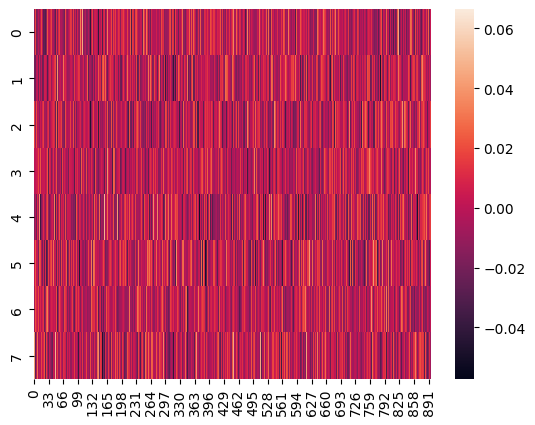

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(embedding[0].cpu().numpy())
plt.show()

In [ ]:
for i, (token, token_id) in enumerate(zip(tokens, ids)):
    vetor = embedding[0, i]
    print(
        f"Token: {token!r:15} "
        f"ID: {token_id:6} "
        f"Dimensão: {vetor.numel()} "
        f"Primeiros valores: {vetor[:8].tolist()}"
    )

Token: 'Que'           ID:  25776 Dimensão: 896 Primeiros valores: [0.026123046875, -0.0118408203125, -0.01092529296875, -0.010498046875, 0.018310546875, -0.025634765625, -0.01806640625, -0.005615234375]
Token: 'Ġa'            ID:    264 Dimensão: 896 Primeiros valores: [0.0084228515625, -0.0203857421875, -0.00171661376953125, -0.0191650390625, -0.0228271484375, 0.000904083251953125, 0.00015926361083984375, -0.01220703125]
Token: 'ĠforÃ§a'       ID: 135192 Dimensão: 896 Primeiros valores: [-0.006103515625, 0.0167236328125, 0.01220703125, -0.008056640625, -0.011474609375, -0.00494384765625, 0.019287109375, 0.0113525390625]
Token: 'Ġeste'         ID:  10351 Dimensão: 896 Primeiros valores: [0.00811767578125, 0.0003566741943359375, 0.0025482177734375, -0.007232666015625, 0.0009918212890625, 0.0206298828125, 0.004638671875, 0.00023651123046875]
Token: 'ja'            ID:   5580 Dimensão: 896 Primeiros valores: [-0.01806640625, -0.0155029296875, 0.0194091796875, -0.010498046875, -0.00045776

In [ ]:
tokens = base_tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0].tolist()
)

In [ ]:
with torch.no_grad():
    saida = base_model(**inputs)

print("Formato dos logits:", tuple(saida.logits.shape))

Formato dos logits: (1, 8, 151936)


In [ ]:
ultimos_logits = saida.logits[0, -1, :]
probabilidades = torch.softmax(ultimos_logits.float(), dim=-1)

top = torch.topk(probabilidades, k=10)

for token_id, prob in zip(top.indices.tolist(), top.values.tolist()):
    token = base_tokenizer.decode([token_id])
    print(f"{token!r:20} {prob:.4%}")

' -'                 18.1723%
' |'                 10.0357%
' –'                 6.2313%
' A'                 3.3615%
' O'                 1.5633%
' Que'               1.1800%
' Qu'                1.1708%
' ('                 0.9783%
' Você'              0.9047%
' E'                 0.8701%


In [ ]:
prompt = "Que a força esteja com você!"

inputs = base_tokenizer(
    prompt,
    return_tensors="pt"
).to(base_model.get_input_embeddings().weight.device)

with torch.no_grad():
    saida = base_model.generate(
        **inputs,
        max_new_tokens=50,
        do_sample=False
    )

resposta = base_tokenizer.decode(
    saida[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print(resposta)

 - Blog do Paulo
Que a força esteja com você!
Publicado em 19/09/2017 19/09/2017 por Paulo
A força é uma força que é a força


### Mais sobre a camada Embedding

$$E \in \mathbb{R}^{151936 \times 896} = \mathbb{R}^{\text{Vocabulario} \times \text{Emded size}} $$

In [ ]:
import torch
import torch.nn as nn

embedding = nn.Embedding(
    num_embeddings=10,
    embedding_dim=4
)

print(embedding.weight.shape)
# torch.Size([10, 4])

ids = torch.tensor([2, 7, 2])
vetores = embedding(ids)

print(vetores.shape)
# torch.Size([3, 4])

print(torch.equal(vetores[0], vetores[2]))
# True

torch.Size([10, 4])
torch.Size([3, 4])
True


In [ ]:
embedding.weight

Parameter containing:
tensor([[-1.3454e+00,  1.4774e-01,  1.1447e+00,  9.6413e-01],
        [-1.4410e+00, -5.7534e-01,  1.3768e+00, -1.8226e+00],
        [ 3.0960e-01,  1.3990e+00, -1.0101e-03, -1.8062e+00],
        [ 2.2419e-02, -1.2256e+00, -2.2390e+00,  1.0279e-01],
        [ 4.2360e-01,  1.6067e-01,  1.1648e+00, -1.7363e+00],
        [-9.8054e-01,  1.2765e+00,  8.0472e-01, -4.3672e-01],
        [ 1.5575e+00, -6.1483e-01, -3.6050e-01,  2.8337e-01],
        [-9.8421e-01, -9.4900e-01, -2.0456e-01,  3.2591e-02],
        [-4.3765e-01, -1.2439e+00, -3.1338e-01, -1.5464e+00],
        [ 7.9905e-01, -8.8836e-02, -2.8563e-01, -3.6047e-01]],
       requires_grad=True)

In [ ]:
E = base_model.model.embed_tokens.weight

print(E.shape)
print(E.requires_grad)
print(E.numel())

torch.Size([151936, 896])
True
136134656


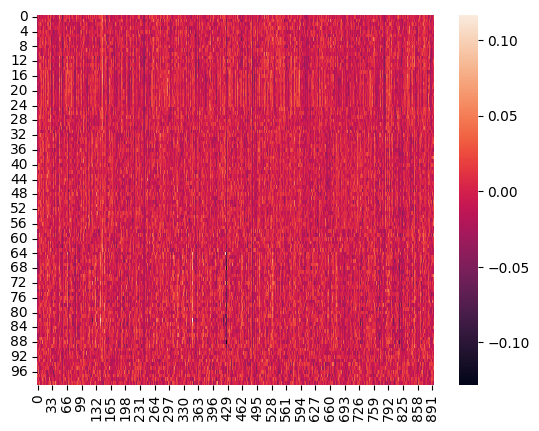

In [ ]:
sns.heatmap(E.cpu().detach().numpy()[0:100,:])
plt.show()

## 3. Criar uma função de geração



In [ ]:
def generate_plain(model, tokenizer, prompt, max_new_tokens=100):
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

def generate_chat(model, tokenizer, user_text, max_new_tokens=100):
    messages = [{"role": "user", "content": user_text}]
    prompt_ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(model.device)

    with torch.no_grad():
        output = model.generate(
            **prompt_ids,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    new_tokens = output[0, prompt_ids["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

## 4. Experimento: base $\times$ instruct

Usamos a mesma pergunta conceitual. O modelo-base recebe um prefixo de continuação, e o modelo Instruct recebe uma mensagem de usuário formatada com seu template de chat.

Essa diferença de formato é intencional: modelos de chat são treinados com estruturas de mensagens e nossa comparação aqui é ilustrativa.

In [ ]:
question = "Explique em português, em duas frases, a diferença entre classificação e regressão."

base_prompt = "Pergunta: " + question + "\nResposta:"
print("=== A. Modelo-base ===")
print(generate_plain(base_model, base_tokenizer, base_prompt, max_new_tokens=100))

print("\n=== B. Modelo Instruct ===")
print(generate_chat(inst_model, inst_tokenizer, question, max_new_tokens=100))

=== A. Modelo-base ===
A diferença entre classificação e regressão está na forma como são calculados os valores de predição. A classificação é a classificação de um objeto ou uma situação em um dos dois valores: 0 (não) ou 1 (sim). Por exemplo, se você estiver classificando um objeto como não pertence a uma categoria, você classifica o objeto como 0. A classificação é uma forma de classificação, mas não é uma forma de predição.

=== B. Modelo Instruct ===
Classificação é o processo de determinar uma classe ou categoria para um conjunto de dados, geralmente usando técnicas como algoritmos de aprendizado de máquina. É útil quando você precisa identificar categorias específicas ou classes que estão presentes em um conjunto de dados.

Regressão, por outro lado, é o processo de prever valores futuros ou resultados dependendo de uma série de variáveis anteriores. É útil quando você precisa prever valores aleatórios ou estim


## 5. Um dataset próprio para SFT

O conjunto aqui é pequeno demais para medir generalização, mas útil para ilustrar o processo.

In [ ]:
examples = [
    ("Classifique o sentimento: 'Adorei o atendimento, foi excelente.'", "Positivo."),
    ("Classifique o sentimento: 'O produto quebrou no primeiro dia.'", "Negativo."),
    ("Classifique o sentimento: 'A entrega chegou no prazo.'", "Positivo."),
    ("Classifique o sentimento: 'Fiquei decepcionado com a compra.'", "Negativo."),
    ("Classifique o sentimento: 'A experiência foi maravilhosa.'", "Positivo."),
    ("Classifique o sentimento: 'O suporte não resolveu meu problema.'", "Negativo."),
    ("Traduza para inglês: 'Bom dia.'", "Good morning."),
    ("Traduza para inglês: 'Muito obrigado pela ajuda.'", "Thank you very much for your help."),
    ("Traduza para inglês: 'O experimento foi concluído.'", "The experiment was completed."),
    ("Traduza para inglês: 'A reunião começa às nove.'", "The meeting starts at nine."),
    ("Traduza para inglês: 'Os resultados são promissores.'", "The results are promising."),
    ("Traduza para inglês: 'Preciso revisar o artigo.'", "I need to review the paper."),
    ("Responda em uma frase: qual é a capital do Brasil?", "A capital do Brasil é Brasília."),
    ("Responda em uma frase: quanto é 7 vezes 8?", "7 vezes 8 é igual a 56."),
    ("Responda em uma frase: quantos lados tem um triângulo?", "Um triângulo tem três lados."),
    ("Responda em uma frase: qual planeta é conhecido como planeta vermelho?", "Marte é conhecido como planeta vermelho."),
    ("Resuma em uma frase: 'A equipe coletou dados durante seis meses. Depois, removeu registros duplicados e avaliou três modelos.'", "A equipe coletou dados por seis meses, removeu duplicatas e avaliou três modelos."),
    ("Resuma em uma frase: 'O método A foi mais rápido, mas teve menor precisão. O método B demorou mais e obteve melhores resultados.'", "O método A foi mais rápido, enquanto o método B foi mais preciso."),
    ("Resuma em uma frase: 'A pesquisa entrevistou 120 participantes e encontrou associação entre sono e desempenho, sem demonstrar causalidade.'", "A pesquisa com 120 participantes encontrou associação entre sono e desempenho, mas não comprovou causalidade."),
    ("Resuma em uma frase: 'O sistema apresentou falhas durante o teste. Após a atualização, os erros diminuíram.'", "Após a atualização, diminuíram as falhas observadas durante o teste do sistema."),
    ("Responda somente com a categoria: um modelo que prevê preço de imóveis realiza classificação ou regressão?", "Regressão."),
    ("Responda somente com a categoria: um modelo que prevê se um e-mail é spam realiza classificação ou regressão?", "Classificação."),
    ("Responda somente com a categoria: agrupar clientes sem rótulos prévios é aprendizado supervisionado ou não supervisionado?", "Não supervisionado."),
    ("Responda somente com a categoria: aprender com exemplos rotulados é aprendizado supervisionado ou não supervisionado?", "Supervisionado.")
]

len(examples)

24

## 6. Preparar os exemplos no formato prompt-completion

Vamos usar o formato `prompt` / `completion`. O treinamento calcula a perda principalmente sobre a resposta desejada (*completion-only loss*), e não sobre a instrução inteira. Esse é um padrão suportado pelo `SFTTrainer` do TRL. Consulte a [documentação do SFTTrainer](https://huggingface.co/docs/trl/main/en/sft_trainer).

In [ ]:
from datasets import Dataset
from trl import SFTConfig, SFTTrainer
from peft import LoraConfig

def make_prompt(instruction):
    return "### Instrução:\n" + instruction.strip() + "\n### Resposta:\n"

rows = [
    {"prompt": make_prompt(instruction), "completion": answer}
    for instruction, answer in examples
]
dataset = Dataset.from_list(rows).shuffle(seed=42)

# Inspecione alguns exemplos antes de treinar.
for item in dataset.select(range(3)):
    print(item["prompt"] + item["completion"])
    print("---")

### Instrução:
Resuma em uma frase: 'A equipe coletou dados durante seis meses. Depois, removeu registros duplicados e avaliou três modelos.'
### Resposta:
A equipe coletou dados por seis meses, removeu duplicatas e avaliou três modelos.
---
### Instrução:
Responda em uma frase: qual planeta é conhecido como planeta vermelho?
### Resposta:
Marte é conhecido como planeta vermelho.
---
### Instrução:
Resuma em uma frase: 'A pesquisa entrevistou 120 participantes e encontrou associação entre sono e desempenho, sem demonstrar causalidade.'
### Resposta:
A pesquisa com 120 participantes encontrou associação entre sono e desempenho, mas não comprovou causalidade.
---


## 7. Treinar um adaptador LoRA com SFT

LoRA congela os pesos principais e treina pequenos adaptadores. Isso reduz a quantidade de parâmetros treináveis. O código usa o modelo-base, e não o modelo Instruct.

In [ ]:
# Recarregamos o modelo-base para garantir que o SFT começa do checkpoint original.
del base_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

base_tokenizer = AutoTokenizer.from_pretrained(BASE_ID)
if base_tokenizer.pad_token is None:
    base_tokenizer.pad_token = base_tokenizer.eos_token

sft_model = AutoModelForCausalLM.from_pretrained(
    BASE_ID, torch_dtype=dtype
)

lora_config = LoraConfig(
    task_type="CAUSAL_LM",
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    bias="none"
)

training_args = SFTConfig(
    output_dir="./qwen25-05b-sft-demo",
    num_train_epochs=3,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    learning_rate=1e-4,
    logging_steps=2,
    save_strategy="no",
    report_to="none",
    max_length=256,
    completion_only_loss=True,
    fp16=(device == "cuda"),
    bf16=False,
    seed=42
)

trainer = SFTTrainer(
    model=sft_model,
    args=training_args,
    train_dataset=dataset,
    peft_config=lora_config,
    processing_class=base_tokenizer
)

trainer.train()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Adding EOS to train dataset:   0%|          | 0/24 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/24 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/24 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/24 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/24 [00:00<?, ? examples/s]

Step,Training Loss
2,1.061498
4,1.096304
6,1.090785
8,0.987519


TrainOutput(global_step=9, training_loss=1.0385098192426894, metrics={'train_runtime': 5.7521, 'train_samples_per_second': 12.517, 'train_steps_per_second': 1.565, 'total_flos': 7198256051712.0, 'train_loss': 1.0385098192426894, 'entropy': 1.560021549463272, 'mean_token_accuracy': 0.7563889026641846, 'num_tokens': 2805.0, 'epoch': 3.0})

## 8. Comparar o modelo-base com o modelo após SFT

Agora avaliamos exatamente o mesmo prefixo no modelo ajustado. O adaptador LoRA contém os parâmetros aprendidos no SFT.

In [ ]:
def generate_sft(model, tokenizer, instruction, max_new_tokens=80):
    prompt = make_prompt(instruction)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    model.eval()
    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

test_prompts = [
    "Classifique o sentimento: 'O serviço foi ótimo e rápido.'",
    "Traduza para inglês: 'A análise dos dados começou hoje.'",
    "Responda em uma frase: quanto é 9 vezes 6?",
    "Responda somente com a categoria: prever a temperatura de amanhã é classificação ou regressão?"
]

for p in test_prompts:
    print("\nINSTRUÇÃO:", p)
    print("SFT:", generate_sft(trainer.model, base_tokenizer, p))


INSTRUÇÃO: Classifique o sentimento: 'O serviço foi ótimo e rápido.'
SFT: 1. O sentimento 'O serviço foi ótimo e rápido.' é positivo, pois o usuário agradeceu o serviço e disse que ele foi rápido.

INSTRUÇÃO: Traduza para inglês: 'A análise dos dados começou hoje.'
SFT: The analysis of the data started today.

INSTRUÇÃO: Responda em uma frase: quanto é 9 vezes 6?
SFT: 9 vezes 6 é igual a 54.

INSTRUÇÃO: Responda somente com a categoria: prever a temperatura de amanhã é classificação ou regressão?
SFT: classificação


**Não confundir SFT com RAG!** aqui o modelo aprende padrões por atualização de parâmetros. RAG, por outro lado, acrescentaria documentos ao contexto durante a inferência.
